# 02 - Feature engineering, model training & experiment tracking
The production training entry-point is `python -m heart.train` (see `src/heart/train.py`). This notebook walks through the same steps and then reads the MLflow results.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

In [2]:
from heart import config
from heart.data import load_clean, split_xy
from heart.features import build_preprocessor
from sklearn.model_selection import train_test_split
df = load_clean(); X, y = split_xy(df)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
pre = build_preprocessor().fit(X_train)
names = pre.named_steps['columns'].get_feature_names_out()
print(len(names), 'model features:'); print(list(names))

24 model features:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca', 'hr_reserve_pct', 'chol_age_ratio', 'sex', 'fbs', 'exang', 'cp_1.0', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'restecg_0.0', 'restecg_1.0', 'restecg_2.0', 'slope_1.0', 'slope_2.0', 'slope_3.0', 'thal_3.0', 'thal_6.0', 'thal_7.0']


In [3]:
pd.DataFrame(pre.transform(X_train), columns=names).describe().T[['mean','std','min','max']].round(2).head(10)

,mean,std,min,max
age,-0.00,1.00,-2.85,2.50
trestbps,-0.00,1.00,-2.10,3.93
chol,0.00,1.00,-2.35,5.96
thalach,-0.00,1.00,-3.49,2.30
oldpeak,0.00,1.00,-0.89,4.64
ca,0.00,1.00,-0.69,2.72
hr_reserve_pct,-0.00,1.00,-3.49,2.12
chol_age_ratio,-0.00,1.00,-2.37,3.45
sex,0.68,0.47,0.00,1.00
fbs,0.14,0.35,0.00,1.00


## Quick baseline comparison (5-fold stratified CV, default hyper-parameters)

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold
from heart.features import build_model_pipeline
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for name, est in {'logreg': LogisticRegression(max_iter=2000), 'rf': RandomForestClassifier(random_state=42), 'gb': GradientBoostingClassifier(random_state=42)}.items():
    s = cross_validate(build_model_pipeline(est), X_train, y_train, cv=cv, scoring=['accuracy','precision','recall','roc_auc'])
    rows.append({'model': name, **{k[5:]: v.mean() for k, v in s.items() if k.startswith('test_')}})
pd.DataFrame(rows).set_index('model').round(3)

,accuracy,precision,recall,roc_auc
model,,,,
logreg,0.843,0.878,0.774,0.906
rf,0.793,0.803,0.738,0.876
gb,0.781,0.761,0.765,0.859


## Tuned results logged to MLflow
Each model family was tuned with `GridSearchCV` (scoring = ROC-AUC). Every grid point is a nested MLflow run. The winner is chosen on **mean CV ROC-AUC**, never on the test set. Ties are broken on recall, because missing a disease case costs more than a false alarm.

In [5]:
import mlflow
mlflow.set_tracking_uri(f"sqlite:///{ROOT/'mlflow.db'}")
runs = mlflow.search_runs(experiment_names=[config.MLFLOW_EXPERIMENT], filter_string="tags.stage = 'tuning'")
cols = ['tags.mlflow.runName','metrics.cv_roc_auc_mean','metrics.cv_accuracy_mean','metrics.cv_recall_mean','metrics.test_roc_auc','metrics.test_accuracy','metrics.test_precision','metrics.test_recall']
runs[cols].round(4)

,tags.mlflow.runName,metrics.cv_roc_auc_mean,metrics.cv_accuracy_mean,metrics.cv_recall_mean,metrics.test_roc_auc,metrics.test_accuracy,metrics.test_precision,metrics.test_recall
0,gradient_boosting,0.8839,0.8139,0.7648,0.9567,0.9016,0.8667,0.9286
1,random_forest,0.8961,0.8098,0.7466,0.9513,0.8852,0.8621,0.8929
2,logistic_regression,0.9075,0.8469,0.8008,0.9589,0.8689,0.8125,0.9286


In [6]:
print('total runs (incl. nested grid points):', len(mlflow.search_runs(experiment_names=[config.MLFLOW_EXPERIMENT])))
meta = json.loads(config.METADATA_FILE.read_text()); meta['model_name'], meta['best_params']

total runs (incl. nested grid points): 80


('logistic_regression',
 {'C': 0.5, 'class_weight': 'balanced', 'penalty': 'l2'})

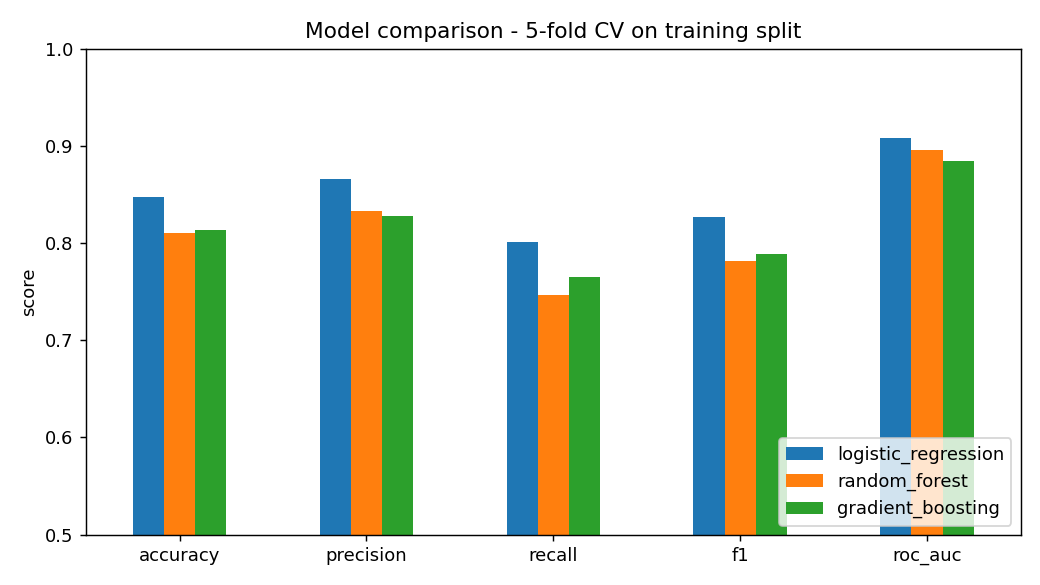

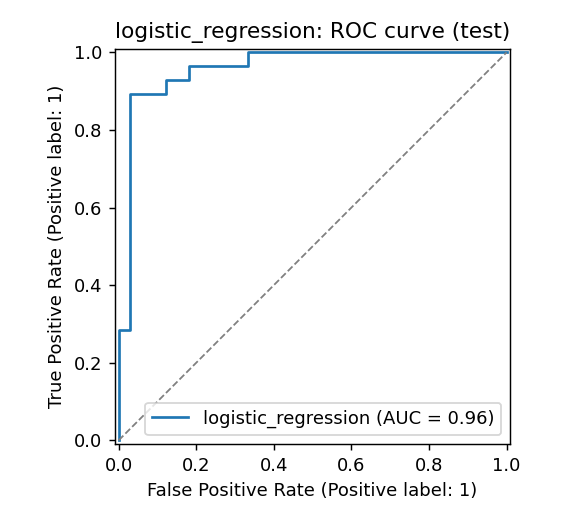

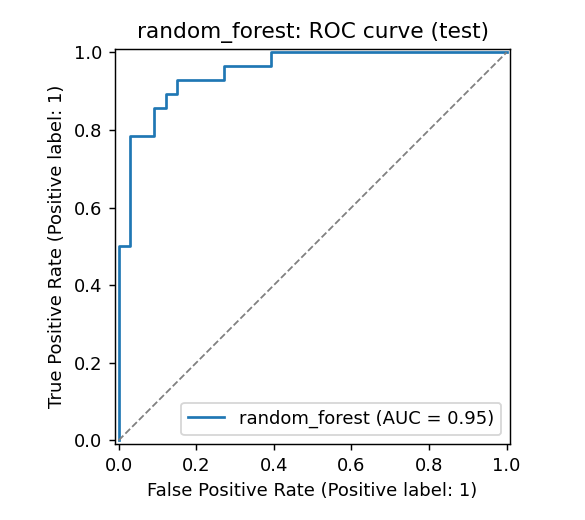

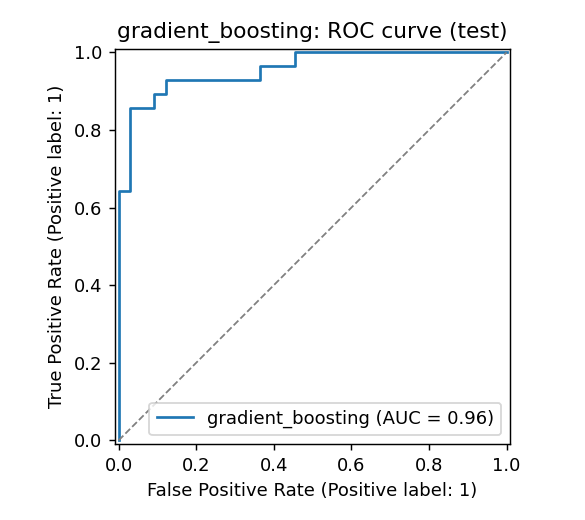

In [7]:
display(Image(config.FIGURES_DIR/'model_comparison.png'))
for m in ['logistic_regression','random_forest','gradient_boosting']:
    display(Image(config.FIGURES_DIR/f'{m}_roc_curve.png'))

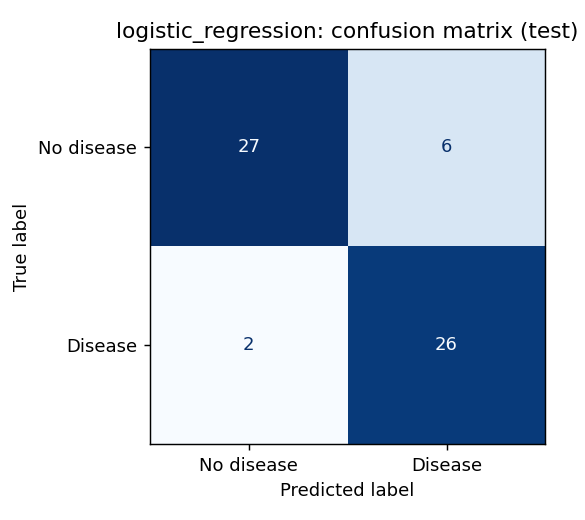

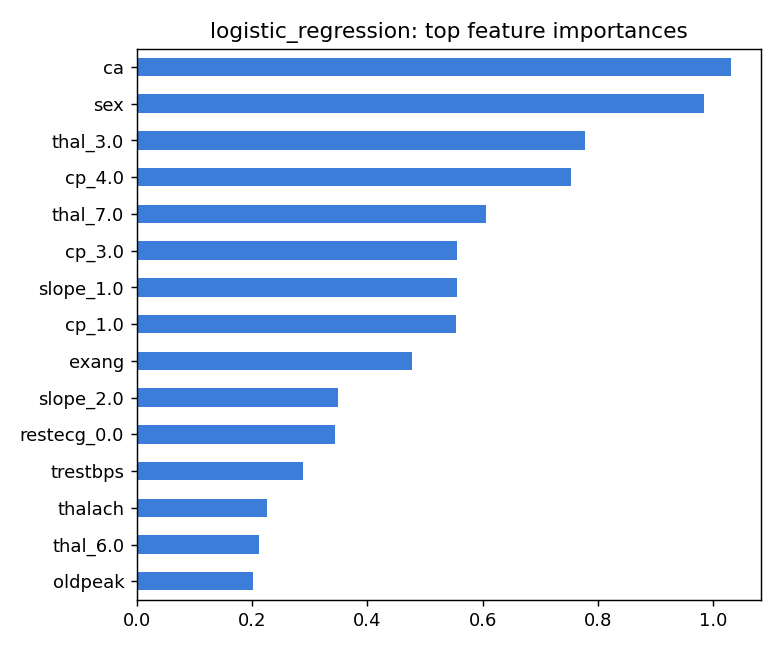

In [8]:
display(Image(config.FIGURES_DIR/'logistic_regression_confusion_matrix.png'))
display(Image(config.FIGURES_DIR/'logistic_regression_feature_importance.png'))